# Convection scheme: first-order upwind against WENO3

Reads the runs written by `generate.py` and timed by `run.py` (`manifest.csv`, `results.csv`). Every case is compared
with a CVODE reference: WENO3 on 400 grid points with a relative tolerance of $10^{-6}$.

Accuracy measures, over the adsorbing feed components $j$ with the outlet mole fraction normalized by its feed value,
$\bar{y}_j=y_j(L,t)/y_{j,\mathrm{in}}$:

- breakthrough time: $e_{50}=\max_j |t_{50,j}-t_{50,j}^{\mathrm{ref}}|/t_{50,j}^{\mathrm{ref}}$ (as in `../breakthrough`);
- breakthrough curve: $E_1=\max_j \frac{1}{t_{\mathrm{end}}}\int_0^{t_{\mathrm{end}}}|\bar{y}_j-\bar{y}_j^{\mathrm{ref}}|\,\mathrm{d}t$;
- front width: $t_{90}-t_{10}$ of the most strongly adsorbed component, relative to the reference.

Output blocks are labelled with the time of the state they hold, so no shift is applied. RK3 runs count as unstable
when they stop or when the outlet exceeds twice the largest roll-up of the reference.

The paper panels are written to `ruptura-2.0-paper/figures/convection/`.

In [1]:
import json
import mmap
import re
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "manifest.csv").is_file():
    raise FileNotFoundError("Run this notebook from benchmark/convection after generate.py and run.py.")
REPOSITORY = ROOT.parents[2]
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "convection"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 13,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.width": 1.0,
    "ytick.minor.width": 1.0,
    "legend.handlelength": 1.2,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
@lru_cache(maxsize=None)
def data_column_index(path_string, heading):
    """Resolve a one-based Ruptura '# column N:' header to a NumPy index (as in ../breakthrough/analysis.ipynb)."""
    prefix = heading.casefold()
    with Path(path_string).open("rt", encoding="utf-8") as handle:
        for line in handle:
            if not line.startswith("#"):
                break
            if line.startswith("# column "):
                number_text, description = line[9:].split(":", 1)
                if description.strip().casefold().startswith(prefix):
                    return int(number_text) - 1
    raise ValueError(f"Column heading {heading!r} not found in {path_string}")


@lru_cache(maxsize=None)
def outlet_rows(path_string):
    """Return the last axial row (the outlet) of every output block (as in ../breakthrough/analysis.ipynb)."""
    rows = []
    with Path(path_string).open("rb") as handle:
        with mmap.mmap(handle.fileno(), length=0, access=mmap.ACCESS_READ) as mapped:
            block_start = 0
            while True:
                block_end = mapped.find(b"\n\n", block_start)
                if block_end < 0:
                    break
                line_start = mapped.rfind(b"\n", block_start, block_end) + 1
                line = mapped[line_start:block_end].strip()
                if line and not line.startswith(b"#"):
                    rows.append(np.array(line.split(), dtype=float))
                block_start = block_end + 2
    return np.asarray(rows)


@lru_cache(maxsize=None)
def outlet_curves(directory):
    """Time [s] and outlet mole fraction normalized by the feed value, per adsorbing feed component."""
    directory = ROOT / "simulations" / directory
    simulation = json.loads((directory / "simulation.json").read_text())
    total = sum(component.get("GasPhaseMolFraction", 0.0) for component in simulation["Components"])
    curves = {}
    for index, component in enumerate(simulation["Components"]):
        if component.get("CarrierGas", False) or component.get("GasPhaseMolFraction", 0.0) <= 0.0:
            continue
        path = str(directory / f"component_{index}_{component['Name']}.data")
        rows = outlet_rows(path)
        time = 60.0 * rows[:, data_column_index(path, "Time, t")]
        fraction = rows[:, data_column_index(path, "Mole fraction")] / (component["GasPhaseMolFraction"] / total)
        order = np.argsort(time, kind="stable")
        curves[component["Name"]] = (time[order], fraction[order])
    return curves


def crossing(time, fraction, level):
    """First time at which the running maximum of a breakthrough curve reaches `level`."""
    rising = np.maximum.accumulate(fraction)
    if rising[-1] < level:
        return np.nan
    i = int(np.argmax(rising >= level))
    return float(np.interp(level, rising[i - 1:i + 1], time[i - 1:i + 1])) if i > 0 else float(time[0])


def front_width(time, fraction):
    """t90 - t10 [s] of a curve normalized by its final value."""
    normalized = fraction / fraction[-1]
    return crossing(time, normalized, 0.9) - crossing(time, normalized, 0.1)


def accuracy(directory, reference):
    """e50, E1, and the relative front width of the most strongly adsorbed component against the reference run."""
    curves, references = outlet_curves(directory), outlet_curves(reference)
    t50_errors, curve_errors = [], []
    for name, (t_ref, y_ref) in references.items():
        t, y = curves[name]
        t50_ref = crossing(t_ref, y_ref, 0.5)
        t50_errors.append(abs(crossing(t, y, 0.5) - t50_ref) / t50_ref)
        curve_errors.append(np.trapezoid(np.abs(np.interp(t_ref, t, y) - y_ref), t_ref) / (t_ref[-1] - t_ref[0]))
    strongest = max(references, key=lambda name: crossing(*references[name], 0.5))
    width = front_width(*curves[strongest]) / front_width(*references[strongest])
    return max(t50_errors), max(curve_errors), width


def largest_outlet_ratio(directory):
    """Largest normalized outlet mole fraction over all adsorbing components and output times."""
    return max(float(np.nanmax(fraction)) for _, fraction in outlet_curves(directory).values())


def cvode_statistics(directory):
    """Internal steps and Krylov iterations reported in run.log (NaN for RK3 runs)."""
    log = (ROOT / "simulations" / directory / "run.log").read_text()
    steps = re.search(r"internal steps:\s+(\d+)", log)
    krylov = re.search(r"krylov iterations:\s+(\d+)", log)
    return (float(steps.group(1)) if steps else np.nan, float(krylov.group(1)) if krylov else np.nan)

In [3]:
MANIFEST = pd.read_csv(ROOT / "manifest.csv")
RESULTS = pd.read_csv(ROOT / "results.csv")
RUNS = MANIFEST.merge(RESULTS, on="directory", how="left")
REFERENCES = RUNS[RUNS["study"] == "reference"].set_index("case")["directory"]
assert (RUNS.loc[RUNS["integrator"] == "cvode", "return_code"] == 0).all()

RUNS["stable"] = [run.return_code == 0
                  and largest_outlet_ratio(run.directory) < 2.0 * largest_outlet_ratio(REFERENCES[run.case])
                  for run in RUNS.itertuples()]
metrics = [accuracy(run.directory, REFERENCES[run.case]) if run.stable else (np.nan, np.nan, np.nan)
           for run in RUNS.itertuples()]
RUNS[["t50_error", "curve_error", "width_ratio"]] = metrics
RUNS[["cvode_steps", "krylov_iterations"]] = [cvode_statistics(run.directory) for run in RUNS.itertuples()]
CASE_NAMES = {"bea-alkanes-C7": "BEA", "marx-T15": "T15", "monolith-400ppm-fitted-dl": "Monolith"}

## Numbers quoted in the paper

In [4]:
cost = RUNS[RUNS["study"] == "cost"].groupby(["case", "integrator", "scheme"]).agg(
    wall=("elapsed_seconds", "mean"), cpu=("cpu_seconds", "mean"), steps=("cvode_steps", "first"),
    krylov=("krylov_iterations", "first"), e50=("t50_error", "first"), E1=("curve_error", "first"),
    width=("width_ratio", "first"))
cost["krylov_per_step"] = cost["krylov"] / cost["steps"]
cost["wall_ratio"] = cost["wall"] / cost.xs("Upwind", level="scheme")["wall"].reindex(
    cost.index.droplevel("scheme")).to_numpy()
with pd.option_context("display.width", 200, "display.float_format", "{:.4g}".format):
    print("Cost and accuracy at the benchmark settings (input grid; RK3 at the benchmark step, CVODE default tolerances)")
    print(cost[["wall", "cpu", "wall_ratio", "steps", "krylov_per_step", "e50", "E1", "width"]])

stability = RUNS[RUNS["study"].isin(["stability", "cost"]) & (RUNS["integrator"] == "rk3")
                 & (RUNS["repeat"] == 1)].pivot_table(index=["case", "time_step"], columns="scheme", values="stable",
                                                      aggfunc="first")
print("\nRK3 stability (True = stable)")
print(stability)

grid = RUNS[RUNS["study"] == "grid"].set_index(["case", "scheme", "grid_points"])[
    ["t50_error", "curve_error", "width_ratio", "elapsed_seconds", "cvode_steps"]]
with pd.option_context("display.width", 200, "display.float_format", "{:.3g}".format):
    print("\nGrid study (CVODE, rtol 1e-6) against WENO3 with 400 grid points")
    print(grid)

Cost and accuracy at the benchmark settings (input grid; RK3 at the benchmark step, CVODE default tolerances)
                                             wall   cpu  wall_ratio     steps  krylov_per_step       e50        E1  width
case                      integrator scheme                                                                              
bea-alkanes-C7            cvode      Upwind 12.85 12.19           1 2.971e+04            3.334   0.00378  0.008085  1.097
                                     WENO3  30.45  28.8       2.369 2.977e+04            8.066 0.0001178 6.213e-05  1.001
                          rk3        Upwind  24.4 23.17           1       NaN              NaN  0.003775  0.008079  1.097
                                     WENO3   26.9 25.52       1.102       NaN              NaN 6.199e-05 0.0001524  1.002
marx-T15                  cvode      Upwind 4.512 2.745           1      1767            7.483   0.02616  0.008898   1.04
                                    

## (a)-(c) Outlet fronts on 25 grid points and on the input grid against the reference

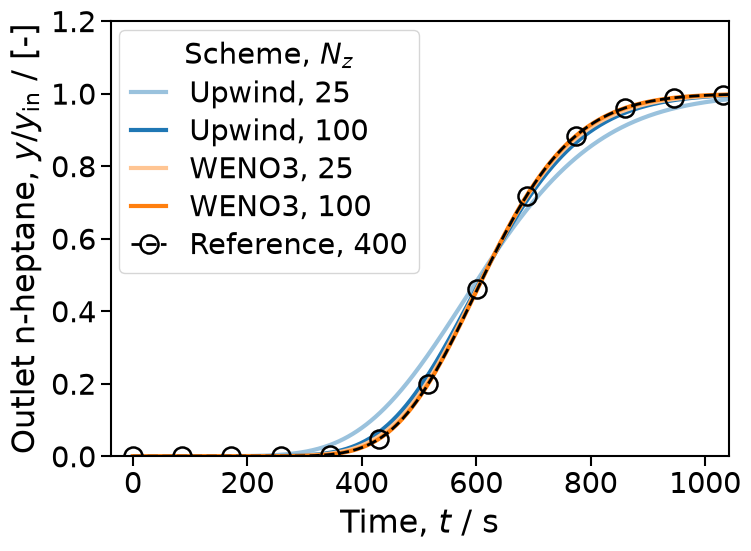

In [5]:
# (a) bea-alkanes-C7: nC7 at the outlet with upwind and WENO3, on 25 grid points (light) and on the input grid
# (dark), against the reference (WENO3, 400 points). All runs: CVODE, rtol 1e-6 (grid study).
from matplotlib.colors import to_rgb

case, component = "bea-alkanes-C7", "nC7"
input_grid = int(RUNS[(RUNS["study"] == "cost") & (RUNS["case"] == case)]["grid_points"].iloc[0])
time_ref, fraction_ref = outlet_curves(REFERENCES[case])[component]
t10, t90 = crossing(time_ref, fraction_ref, 0.1), crossing(time_ref, fraction_ref, 0.9)
# Wider on the left, so that the legend sits before the front.
window = (t10 - 1.6 * (t90 - t10), t90 + 0.8 * (t90 - t10))


def lighter(color, amount):
    base = np.array(to_rgb(color))
    return tuple(base + amount * (np.ones(3) - base))


fig, ax = plt.subplots()
for scheme, color in (("Upwind", "C0"), ("WENO3", "C1")):
    for grid_points, shade in ((25, 0.55), (input_grid, 0.0)):
        run = RUNS[(RUNS["study"] == "grid") & (RUNS["case"] == case) & (RUNS["scheme"] == scheme)
                   & (RUNS["grid_points"] == grid_points)]
        time, fraction = outlet_curves(run["directory"].iloc[0])[component]
        ax.plot(time, fraction, color=lighter(color, shade), linestyle="-", label=f"{scheme}, {grid_points}")
inside = (time_ref >= window[0]) & (time_ref <= window[1])
ax.plot(time_ref, fraction_ref, color="black", linestyle="--", linewidth=2.0, marker="o", markerfacecolor="none",
        markevery=max(1, int(inside.sum() / 12)), label="Reference, 400")
ax.set_xlim(*window)
ax.set_ylim(0.0, 1.2 * max(1.0, float(np.max(fraction_ref[inside]))))
ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Outlet n-heptane, $y/y_{\mathrm{in}}$ / [-]")
ax.legend(loc="upper left", title="Scheme, $N_z$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "convection_bea.pdf", dpi=300)
plt.show()

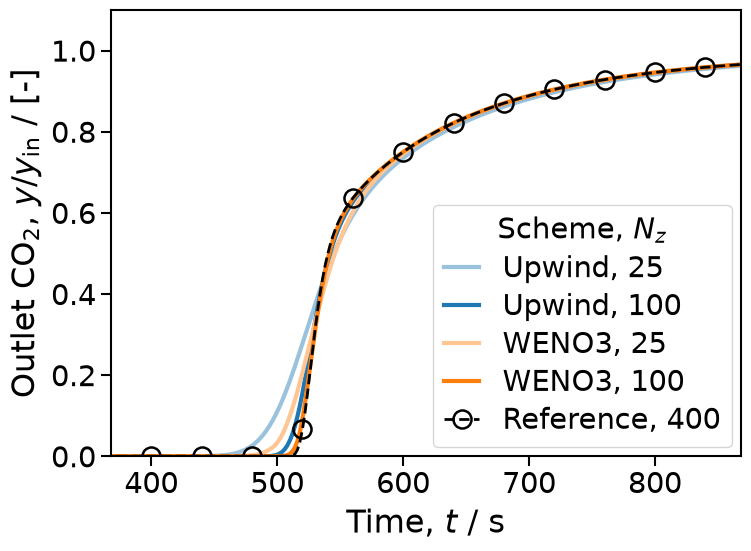

In [6]:
# (b) marx-T15: CO2 at the outlet with upwind and WENO3, on 25 grid points (light) and on the input grid
# (dark), against the reference (WENO3, 400 points). All runs: CVODE, rtol 1e-6 (grid study).
from matplotlib.colors import to_rgb

case, component = "marx-T15", "CO2"
input_grid = int(RUNS[(RUNS["study"] == "cost") & (RUNS["case"] == case)]["grid_points"].iloc[0])
time_ref, fraction_ref = outlet_curves(REFERENCES[case])[component]
t10, t90 = crossing(time_ref, fraction_ref, 0.1), crossing(time_ref, fraction_ref, 0.9)
window = (t10 - 0.8 * (t90 - t10), t90 + 0.8 * (t90 - t10))


def lighter(color, amount):
    base = np.array(to_rgb(color))
    return tuple(base + amount * (np.ones(3) - base))


fig, ax = plt.subplots()
for scheme, color in (("Upwind", "C0"), ("WENO3", "C1")):
    for grid_points, shade in ((25, 0.55), (input_grid, 0.0)):
        run = RUNS[(RUNS["study"] == "grid") & (RUNS["case"] == case) & (RUNS["scheme"] == scheme)
                   & (RUNS["grid_points"] == grid_points)]
        time, fraction = outlet_curves(run["directory"].iloc[0])[component]
        ax.plot(time, fraction, color=lighter(color, shade), linestyle="-", label=f"{scheme}, {grid_points}")
inside = (time_ref >= window[0]) & (time_ref <= window[1])
ax.plot(time_ref, fraction_ref, color="black", linestyle="--", linewidth=2.0, marker="o", markerfacecolor="none",
        markevery=max(1, int(inside.sum() / 12)), label="Reference, 400")
ax.set_xlim(*window)
ax.set_ylim(0.0, 1.1 * max(1.0, float(np.max(fraction_ref[inside]))))
ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Outlet CO$_2$, $y/y_{\mathrm{in}}$ / [-]")
ax.legend(loc="lower right", title="Scheme, $N_z$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "convection_t15.pdf", dpi=300)
plt.show()

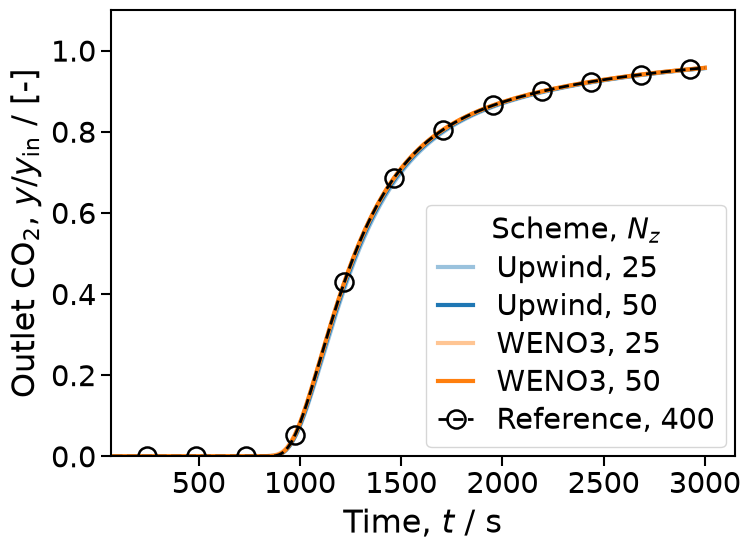

In [7]:
# (c) monolith-400ppm-fitted-dl: CO2 at the outlet with upwind and WENO3, on 25 grid points (light) and on the input grid
# (dark), against the reference (WENO3, 400 points). All runs: CVODE, rtol 1e-6 (grid study).
from matplotlib.colors import to_rgb

case, component = "monolith-400ppm-fitted-dl", "CO2"
input_grid = int(RUNS[(RUNS["study"] == "cost") & (RUNS["case"] == case)]["grid_points"].iloc[0])
time_ref, fraction_ref = outlet_curves(REFERENCES[case])[component]
t10, t90 = crossing(time_ref, fraction_ref, 0.1), crossing(time_ref, fraction_ref, 0.9)
window = (t10 - 0.8 * (t90 - t10), t90 + 0.8 * (t90 - t10))


def lighter(color, amount):
    base = np.array(to_rgb(color))
    return tuple(base + amount * (np.ones(3) - base))


fig, ax = plt.subplots()
for scheme, color in (("Upwind", "C0"), ("WENO3", "C1")):
    for grid_points, shade in ((25, 0.55), (input_grid, 0.0)):
        run = RUNS[(RUNS["study"] == "grid") & (RUNS["case"] == case) & (RUNS["scheme"] == scheme)
                   & (RUNS["grid_points"] == grid_points)]
        time, fraction = outlet_curves(run["directory"].iloc[0])[component]
        ax.plot(time, fraction, color=lighter(color, shade), linestyle="-", label=f"{scheme}, {grid_points}")
inside = (time_ref >= window[0]) & (time_ref <= window[1])
ax.plot(time_ref, fraction_ref, color="black", linestyle="--", linewidth=2.0, marker="o", markerfacecolor="none",
        markevery=max(1, int(inside.sum() / 12)), label="Reference, 400")
ax.set_xlim(*window)
ax.set_ylim(0.0, 1.1 * max(1.0, float(np.max(fraction_ref[inside]))))
ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Outlet CO$_2$, $y/y_{\mathrm{in}}$ / [-]")
ax.legend(loc="lower right", title="Scheme, $N_z$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "convection_monolith.pdf", dpi=300)
plt.show()

## (d) Accuracy against cost: grid study with CVODE

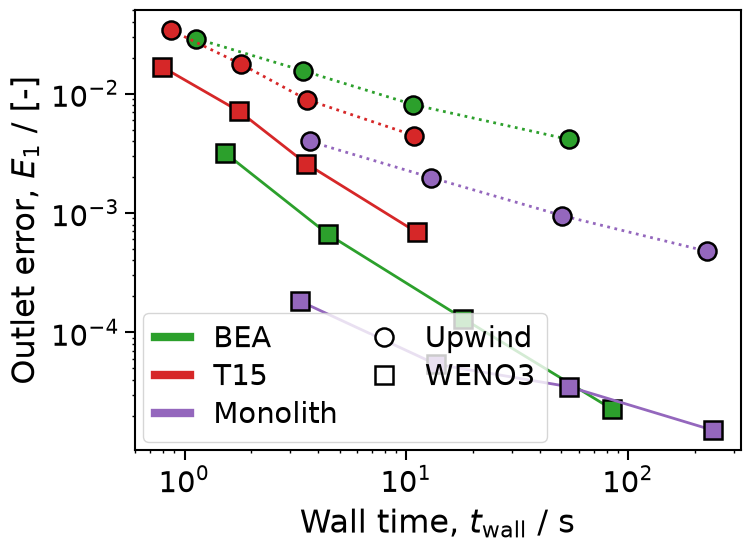

In [8]:
# (d) Outlet-curve error E1 against wall time for N = 25, 50, 100, 200 (CVODE, rtol 1e-6); one colour per case,
# circles upwind, squares WENO3.
cases = (("bea-alkanes-C7", "BEA", "C2"), ("marx-T15", "T15", "C3"), ("monolith-400ppm-fitted-dl", "Monolith", "C4"))

fig, ax = plt.subplots()
for case, name, color in cases:
    for scheme, marker, style in (("Upwind", "o", ":"), ("WENO3", "s", "-")):
        points = RUNS[(RUNS["study"] == "grid") & (RUNS["case"] == case) & (RUNS["scheme"] == scheme)].sort_values(
            "grid_points")
        ax.plot(points["elapsed_seconds"], points["curve_error"], color=color, marker=marker, markeredgecolor="black",
                linestyle=style, linewidth=2.0)
    ax.plot([], [], color=color, linewidth=6.0, label=name)
ax.plot([], [], color="white", marker="o", markeredgecolor="black", linestyle=":", label="Upwind")
ax.plot([], [], color="white", marker="s", markeredgecolor="black", linestyle="-", label="WENO3")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Wall time, $t_{\mathrm{wall}}$ / s")
ax.set_ylabel(r"Outlet error, $E_1$ / [-]")
ax.legend(loc="lower left", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "convection_precision.pdf", dpi=300)
plt.show()